# Time on: which teams finish quarters best?

An AFL quarter is 20 minutes plus **time on**: stoppage time that builds up during
the quarter and is played after the 20-minute mark. AFL Tables' scoring
progression gives every score's time within its quarter and each quarter's
actual length. So each score can be labelled **regular time** (the first 20
minutes) or **time on** (after 20:00), and scoring can be compared **per minute**.

**Question:** which teams do relatively better or worse in time on than in
regular time?

**Data:** every 2025 and 2026 match page on AFL Tables (home-and-away and
finals), parsed by `src/afl/scoring.py`. Each match's summed points are checked
against its scoreboard. The team analysis pools both seasons, and section 4
compares them.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.transforms import Bbox

from afl.analysis import bootstrap
from afl.draft_charts import BLUE, BLUE_BAND, GREY, INK, ORANGE, TITLE, apply_style
from afl.scoring import season_scoring

YEARS = [2025, 2026]
REGULAR_SECONDS = 20 * 60
N_BOOT = 2000
pd.set_option("display.width", 200)
apply_style()


def label_points(ax, xs, ys, names):
    """Label scatter points without overlaps.

    For each point, try a few spots around it (right, below-right, left, above,
    below) and keep the first whose drawn text box doesn't overlap a label
    already placed or any dot. Falls back to the right-hand spot if all are taken.
    """
    spots = [((5, 2), "left"), ((5, -10), "left"), ((-5, 2), "right"),
             ((-5, -10), "right"), ((5, 13), "left"), ((5, -21), "left")]
    short = {"Greater Western Sydney": "GWS", "Brisbane Lions": "Brisbane", "Western Bulldogs": "Bulldogs"}
    renderer = ax.figure.canvas.get_renderer()
    # Start with a small box around every dot, so labels avoid dots as well as each other
    boxes = [Bbox.from_bounds(px - 4, py - 4, 8, 8)
             for px, py in ax.transData.transform(np.column_stack([xs, ys]))]
    for x, y, name in zip(xs, ys, [short.get(n, n) for n in names]):
        for offset, align in spots:
            label = ax.annotate(name, (x, y), xytext=offset, textcoords="offset points",
                                ha=align, fontsize=8, color=TITLE)
            box = label.get_window_extent(renderer).expanded(1.05, 1.15)
            if not any(box.overlaps(b) for b in boxes):
                break
            label.remove()
        else:
            label = ax.annotate(name, (x, y), xytext=spots[0][0], textcoords="offset points",
                                fontsize=8, color=TITLE)
            box = label.get_window_extent(renderer)
        boxes.append(box)

loaded = [season_scoring(year) for year in YEARS]
events = pd.concat([e.assign(season=y) for (e, _), y in zip(loaded, YEARS)], ignore_index=True)
quarters = pd.concat([q.assign(season=y) for (_, q), y in zip(loaded, YEARS)], ignore_index=True)

matches = quarters.drop_duplicates("match")
summary = matches.groupby("season").agg(matches=("match", "size"), valid=("valid", "sum"))
summary["finals"] = matches[~matches["round"].str.isdigit()].groupby("season").size()
summary["scoring events"] = events.groupby("season").size()
summary

,matches,valid,finals,scoring events
season,,,,
2025,216,216,9,9975
2026,218,218,11,10722


## 1. How long is time on?

Regular time is always 20 minutes. Time on is whatever comes after.

In [2]:
quarters["time_on_minutes"] = (quarters["length_seconds"] - REGULAR_SECONDS).clip(lower=0) / 60
quarters["regular_minutes"] = quarters["length_seconds"].clip(upper=REGULAR_SECONDS) / 60
print(f"Quarters shorter than 20 minutes: {(quarters['length_seconds'] < REGULAR_SECONDS).sum()}")
quarters.groupby("quarter")["time_on_minutes"].describe()[["mean", "min", "50%", "max"]].round(1)

Quarters shorter than 20 minutes: 0


,mean,min,50%,max
quarter,,,,
1,11.4,6.4,11.1,22.8
2,11.4,5.0,11.5,18.0
3,11.6,5.2,11.5,21.0
4,11.6,2.9,11.5,22.2


## 2. League-wide: is scoring faster in time on?

Points scored by both teams per 10 minutes, in regular time and in time on, for
each quarter.

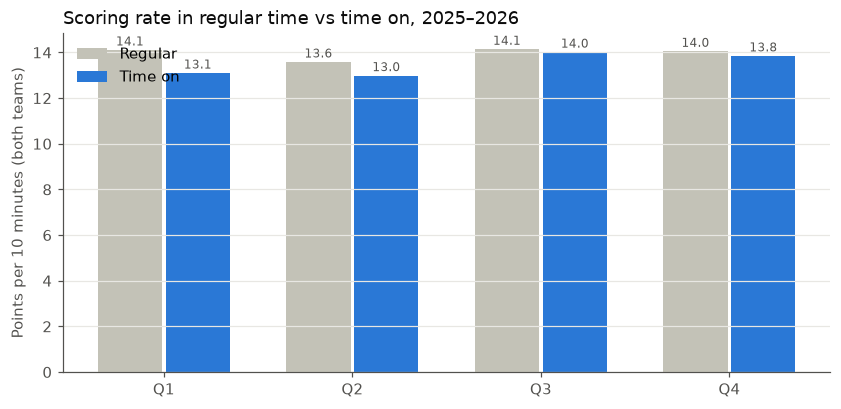

period,Regular,Time on
quarter,,
1,14.10,13.09
2,13.58,12.98
3,14.13,14.01
4,14.04,13.84


In [3]:
events["period"] = np.where(events["seconds"] >= REGULAR_SECONDS, "Time on", "Regular")

rows = []
for q in [1, 2, 3, 4]:
    qe, qq = events[events["quarter"] == q], quarters[quarters["quarter"] == q]
    for period, minutes in [("Regular", qq["regular_minutes"].sum()), ("Time on", qq["time_on_minutes"].sum())]:
        points = qe.loc[qe["period"] == period, "points"].sum()
        rows.append({"quarter": q, "period": period, "minutes": minutes, "points": points,
                     "points per 10 min": points / minutes * 10})
league = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(4)
for offset, (period, colour) in zip([-0.18, 0.18], [("Regular", GREY), ("Time on", BLUE)]):
    part = league[league["period"] == period]
    ax.bar(x + offset, part["points per 10 min"], width=0.34, color=colour, label=period)
    for xi, value in zip(x + offset, part["points per 10 min"]):
        ax.annotate(f"{value:.1f}", (xi, value), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=8, color=INK)
ax.set_xticks(x, ["Q1", "Q2", "Q3", "Q4"])
ax.set_ylabel("Points per 10 minutes (both teams)")
ax.grid(axis="x", visible=False)
ax.set_title("Scoring rate in regular time vs time on, 2025–2026", loc="left", color=TITLE)
ax.legend(frameon=False, loc="upper left")
plt.show()
league.pivot(index="quarter", columns="period", values="points per 10 min").round(2)

## 3. By team: who does relatively better in time on?

For each team and each match: points **for** and **against** in regular time
and in time on, and the minutes played in each.

- **Margin per 10 minutes** = (points for − points against) ÷ minutes × 10,
  for regular time and for time on separately.
- **Time-on edge** = time-on margin minus regular-time margin.
  - Positive: the team does *relatively better* in time on than its overall
    strength suggests.
  - Negative: it fades in time on.
- **Intervals:** 95% bootstrap intervals from resampling the team's matches
  (2,000 resamples).

Strong teams will be positive in both periods. The edge removes that, so it
shows what's specific to time on.

In [4]:
def team_matches(events, quarters):
    """One row per team per match: points for and against in each period, and minutes."""
    games = quarters.drop_duplicates("match")[["match", "season", "home", "away"]]
    rows = pd.concat([games.rename(columns={"home": "team", "away": "opponent"}),
                      games.rename(columns={"away": "team", "home": "opponent"})], ignore_index=True)
    scored = events.groupby(["match", "team", "period"])["points"].sum().unstack(fill_value=0)
    assert list(scored.columns) == ["Regular", "Time on"]
    for side, key in [("for", "team"), ("against", "opponent")]:
        pts = scored.reindex(pd.MultiIndex.from_frame(rows[["match", key]])).fillna(0).to_numpy()
        rows[f"regular_{side}"] = pts[:, 0]
        rows[f"time_on_{side}"] = pts[:, 1]
    minutes = quarters.groupby("match")[["regular_minutes", "time_on_minutes"]].sum()
    return rows.join(minutes, on="match")


teams = team_matches(events, quarters)


def margins(d):
    """Regular-time margin, time-on margin and their difference, per 10 minutes."""
    regular = (d["regular_for"].sum() - d["regular_against"].sum()) / d["regular_minutes"].sum() * 10
    time_on = (d["time_on_for"].sum() - d["time_on_against"].sum()) / d["time_on_minutes"].sum() * 10
    return regular, time_on, time_on - regular


rows = []
for team, d in teams.groupby("team"):
    regular, time_on, edge = margins(d)
    est, low, high = bootstrap(d, lambda x: margins(x)[2], n=N_BOOT)
    rows.append({"team": team, "matches": len(d), "time-on minutes": d["time_on_minutes"].sum(),
                 "regular margin /10 min": regular, "time-on margin /10 min": time_on,
                 "time-on edge": edge, "low": low, "high": high})
by_team = pd.DataFrame(rows).set_index("team").sort_values("time-on edge", ascending=False)
by_team.round(2)

,matches,time-on minutes,regular margin /10 min,time-on margin /10 min,time-on edge,low,high
team,,,,,,,
Richmond,46,2021.68,-3.34,-2.02,1.32,-0.02,2.72
Greater Western Sydney,47,2240.43,-0.04,1.13,1.17,-0.60,2.83
North Melbourne,46,2170.28,-1.78,-0.68,1.10,-0.28,2.45
St Kilda,46,2094.28,-0.69,0.35,1.04,-0.63,2.81
Collingwood,49,2195.42,0.34,1.23,0.89,-0.74,2.49
Gold Coast,48,2215.00,0.22,0.81,0.59,-0.88,2.01
Geelong,51,2426.03,1.71,1.99,0.28,-1.25,1.83
Port Adelaide,46,2103.45,-1.21,-1.10,0.11,-1.32,1.65
Fremantle,51,2253.85,1.21,1.22,0.02,-1.30,1.38


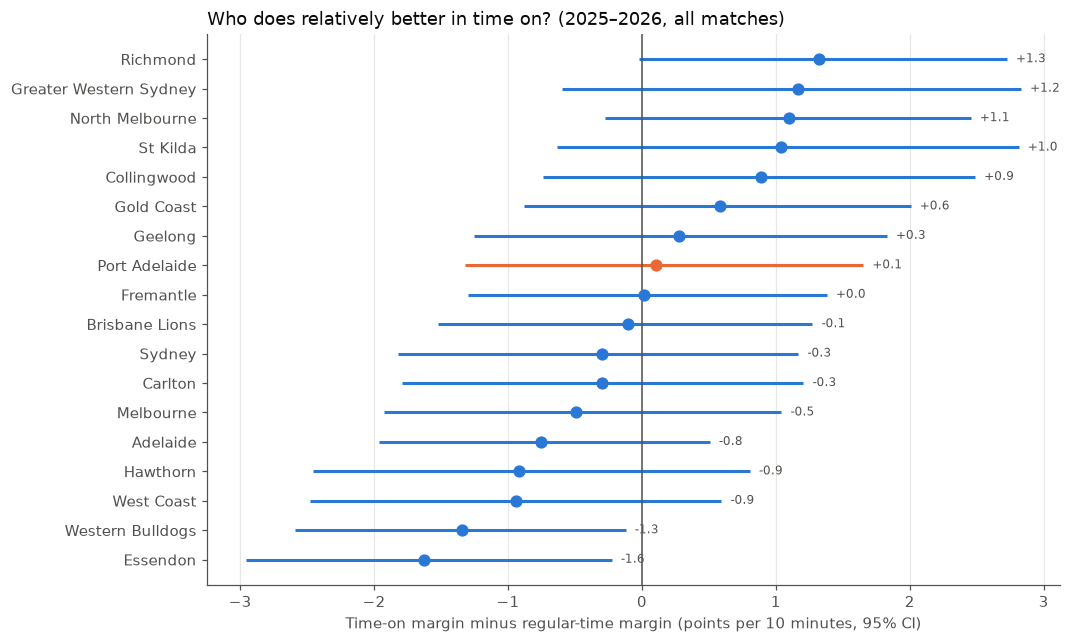

In [5]:
plot = by_team.sort_values("time-on edge")
fig, ax = plt.subplots(figsize=(10, 6.5))
y = np.arange(len(plot))
for yi, (team, row) in zip(y, plot.iterrows()):
    colour = ORANGE if team == "Port Adelaide" else BLUE
    ax.errorbar(row["time-on edge"], yi, xerr=[[row["time-on edge"] - row["low"]], [row["high"] - row["time-on edge"]]],
                fmt="o", color=colour, markersize=7, capsize=0, elinewidth=2)
    ax.annotate(f"{row['time-on edge']:+.1f}", (row["high"], yi), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8, color=INK)
ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(y, plot.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Time-on margin minus regular-time margin (points per 10 minutes, 95% CI)")
ax.set_title("Who does relatively better in time on? (2025–2026, all matches)", loc="left", color=TITLE)
plt.show()

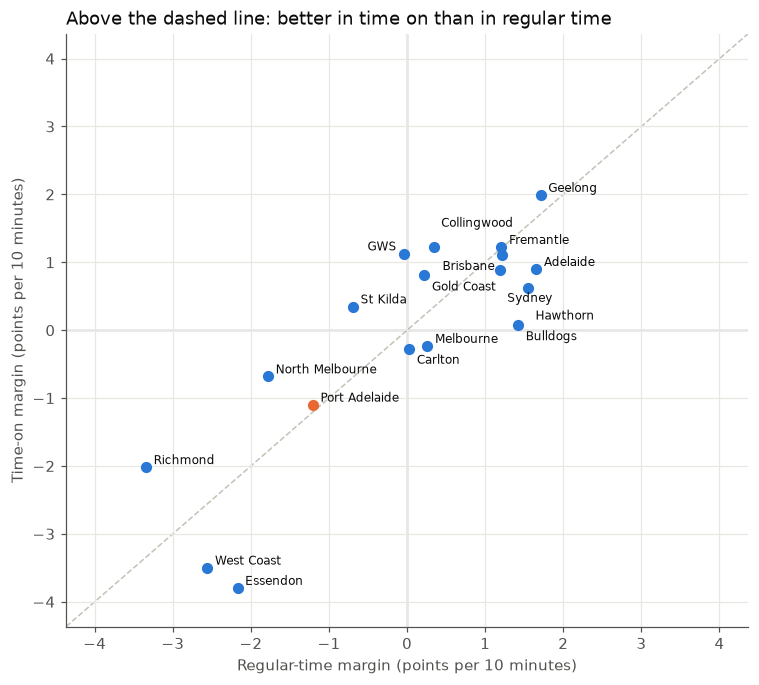

In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
lim = max(by_team[["regular margin /10 min", "time-on margin /10 min"]].abs().max()) * 1.15
ax.plot([-lim, lim], [-lim, lim], color=GREY, linewidth=1, linestyle="--", zorder=0)
ax.axhline(0, color=INK, linewidth=0.8, zorder=0)
ax.axvline(0, color=INK, linewidth=0.8, zorder=0)
for team, row in by_team.iterrows():
    colour = ORANGE if team == "Port Adelaide" else BLUE
    ax.scatter(row["regular margin /10 min"], row["time-on margin /10 min"], s=40, color=colour, zorder=3)
label_points(ax, by_team["regular margin /10 min"], by_team["time-on margin /10 min"], by_team.index)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("Regular-time margin (points per 10 minutes)")
ax.set_ylabel("Time-on margin (points per 10 minutes)")
ax.set_title("Above the dashed line: better in time on than in regular time", loc="left", color=TITLE)
plt.show()

## 4. Do teams lean the same way in both seasons?

If some teams really are better (or worse) in time on, their edge in 2025
should look like their edge in 2026. If the edges are mostly noise, the two
seasons won't line up.

Correlation between teams' 2025 and 2026 edges: 0.16


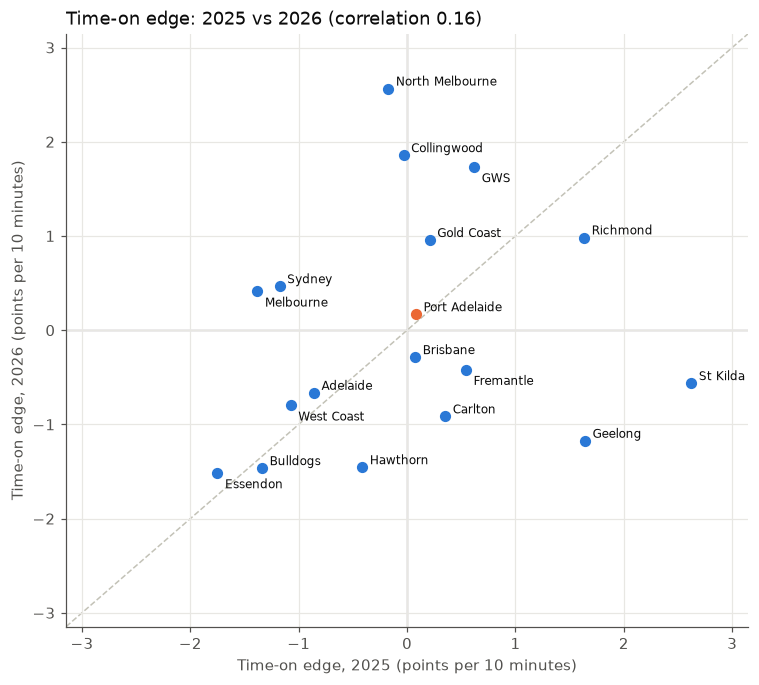

,edge 2025,edge 2026
North Melbourne,-0.17,2.56
Collingwood,-0.03,1.86
Greater Western Sydney,0.62,1.73
Richmond,1.63,0.98
Gold Coast,0.21,0.96
Sydney,-1.18,0.47
Melbourne,-1.38,0.41
Port Adelaide,0.08,0.17
Brisbane Lions,0.07,-0.29
Fremantle,0.54,-0.42


In [7]:
by_season = pd.DataFrame({
    f"edge {year}": {team: margins(d)[2] for team, d in teams[teams["season"] == year].groupby("team")}
    for year in YEARS
})
corr = by_season.corr().iloc[0, 1]
print(f"Correlation between teams' 2025 and 2026 edges: {corr:.2f}")

fig, ax = plt.subplots(figsize=(8, 7))
lim = by_season.abs().max().max() * 1.2
ax.axhline(0, color=INK, linewidth=0.8, zorder=0)
ax.axvline(0, color=INK, linewidth=0.8, zorder=0)
ax.plot([-lim, lim], [-lim, lim], color=GREY, linewidth=1, linestyle="--", zorder=0)
for team, row in by_season.iterrows():
    colour = ORANGE if team == "Port Adelaide" else BLUE
    ax.scatter(row["edge 2025"], row["edge 2026"], s=40, color=colour, zorder=3)
label_points(ax, by_season["edge 2025"], by_season["edge 2026"], by_season.index)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("Time-on edge, 2025 (points per 10 minutes)")
ax.set_ylabel("Time-on edge, 2026 (points per 10 minutes)")
ax.set_title(f"Time-on edge: 2025 vs 2026 (correlation {corr:.2f})", loc="left", color=TITLE)
plt.show()
by_season.sort_values("edge 2026", ascending=False).round(2)

## 5. Check: quarters 1–3 only

In final-quarter time on, the result is often already decided, and the leading
team may simply play it safe. Leaving out the fourth quarter checks that the
team pattern isn't just about how teams protect a lead.

In [8]:
teams13 = team_matches(events[events["quarter"] <= 3], quarters[quarters["quarter"] <= 3])

# Also: how much smaller are time-on margins than regular-time margins, across teams?
slope = np.polyfit(by_team["regular margin /10 min"], by_team["time-on margin /10 min"], 1)[0]
print(f"Time-on margins are about {slope:.0%} the size of regular-time margins "
      f"(slope across teams); edge vs team strength correlation: "
      f"{by_team['regular margin /10 min'].corr(by_team['time-on edge']):.2f}")

compare = pd.DataFrame({
    "edge, all quarters": by_team["time-on edge"],
    "edge, Q1-Q3 only": {team: margins(d)[2] for team, d in teams13.groupby("team")},
}).sort_values("edge, all quarters", ascending=False)
print(f"Correlation between the two: {compare.corr().iloc[0, 1]:.2f}")
compare.round(2)

Time-on margins are about 87% the size of regular-time margins (slope across teams); edge vs team strength correlation: -0.23
Correlation between the two: 0.89


,"edge, all quarters","edge, Q1-Q3 only"
Richmond,1.32,1.01
Greater Western Sydney,1.17,1.09
North Melbourne,1.10,0.84
St Kilda,1.04,1.11
Collingwood,0.89,1.31
Gold Coast,0.59,0.37
Geelong,0.28,0.25
Port Adelaide,0.11,-0.43
Fremantle,0.02,0.84
Brisbane Lions,-0.11,-1.06


# Results

## Data

- **All 434 matches of 2025 and 2026** were parsed: 216 and 218, including 9
  and 11 finals. 2026 added two Wildcard Finals.
- **Every match's summed points equal its scoreboard.**
- **20,697 scoring events.** Every quarter ran longer than 20 minutes.

## League-wide

- **Time on averages about 11.5 minutes a quarter**, so a quarter typically runs
  about 31–32 minutes.
- **Scoring is a little slower in time on in the first half:** in Q1, 13.1 vs
  14.1 points per 10 minutes, and in Q2, 13.0 vs 13.6 (about 4–7% slower). In
  the second half the two are nearly equal (Q3 14.0 vs 14.1; Q4 13.8 vs 14.0).
- 2026 alone suggested a third-quarter dip as well, which disappears with two
  seasons. It's a small reminder of how noisy one season is.

## By team

- **With two seasons pooled, two teams' intervals sit below zero:**
  - **Essendon:** −1.6 points per 10 minutes (CI −3.0 to −0.2)
  - **Western Bulldogs:** −1.3 (CI −2.6 to −0.1)
  - Richmond is just short on the positive side (+1.3, CI −0.0 to +2.7).
  - With 18 teams, about 1 would get there by chance.
- **Edges mostly don't carry over between seasons.** The correlation between
  teams' 2025 and 2026 edges is only **0.16**. For example:
  - North Melbourne: −0.2 in 2025, then +2.6 in 2026
  - St Kilda: +2.6, then −0.6
  - Geelong: +1.6, then −1.2

  Most of what looks like a "time-on team" in a single season is noise.
- **The exceptions are Essendon and the Western Bulldogs.** They faded in time on
  in *both* seasons (Essendon −1.8 and −1.5; Bulldogs −1.3 and −1.5). That's the
  only consistent pattern, though with 18 teams a pair like this could still
  arise by chance.
- **Port Adelaide: +0.1 (CI −1.3 to +1.7)**, and close to zero in both seasons
  (+0.1 and +0.2). Port plays time on exactly as it plays regular time.
- **The fourth quarter doesn't drive the pattern.** Leaving it out gives nearly
  the same team edges (correlation 0.89).
- **Margins shrink in time on**, to about **87%** of their regular-time size
  across the two seasons. One season alone suggested 75%. That gives weak teams
  a small built-in positive edge (correlation of edge with team strength: −0.23).

## What this adds up to

- **Time on is slightly lower-scoring early in matches, and margins narrow a
  little in it.**
- **There's little evidence of lasting "time-on teams".** Team differences in one
  season mostly vanish in the next.
- **The one pattern worth watching** is Essendon and the Western Bulldogs fading
  in time on in both seasons. Adding 2024 would show whether it continues.

## Possible next steps

1. **Check whether Essendon and the Bulldogs keep fading:** add 2024 (about 216
   more pages), with the rule written down first.
2. **Game state:** in time on, do leading teams score less and trailing teams
   more? That would directly explain why margins shrink.